In [8]:
# standard libraries
import os, sys, json, time, glob
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from skimage.metrics import peak_signal_noise_ratio as psnr

# your project modules (run from the ambient_flow_MRI folder)
sys.path.append(os.getcwd())
from model.model import build_unet, UNetVelocity
from loss.loss import ambient_loss
from data.data import BrainAmbientFlowMatchingDataset
from util.helper import fft2c, ifft2c, rss, show, cartesian_mask, infinite, plot_recon

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [14]:
N_COILS = 16
DELTA, EPS, LR = 0.1, 1e-3, 1e-4
BATCH_SIZE = 4
MAX_STEPS, print_every, val_every, ckpt_every = 10000, 1000, 100, 2000
ckpt_dir = "/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/ckpt_ambient_fm"; os.makedirs(ckpt_dir, exist_ok=True)

In [21]:
split_index = json.load(open("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/split_16x320x320.json"))
train_set = BrainAmbientFlowMatchingDataset(index=split_index["train"], accel=4, cf=0.08)
val_set   = BrainAmbientFlowMatchingDataset(index=split_index["val"],   accel=4, cf=0.08)
test_set  = BrainAmbientFlowMatchingDataset(index=split_index["test"],  accel=4, cf=0.08)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                                           num_workers=4, pin_memory=True, drop_last=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

train_data_iter = infinite(train_loader)
val_data_iter = infinite(val_loader)
test_data_iter = infinite(test_loader)

train_losses = []
val_losses = []
test_losses = []

val_steps = []

y, A, _ = next(train_data_iter)
print("y", tuple(y.shape), "| A", tuple(A.shape))       # (4, 16, 320, 320) | (4, 1, 1, 320)

y (4, 16, 320, 320) | A (4, 1, 1, 320)


11438 slices
index16[10] = /egr/research-slim/shared/brain_multicoil/train/multicoil_train_npz/file_brain_AXFLAIR_200_6002435/slice_10.npz
kspace               (16, 320, 320)       complex64
target               (320, 320)           float32
acquisition          ()                   <U7
max                  ()                   float64
norm                 ()                   float64
patient_id           ()                   <U64
coils=16, H=320, W=320 | 224/320 columns sampled


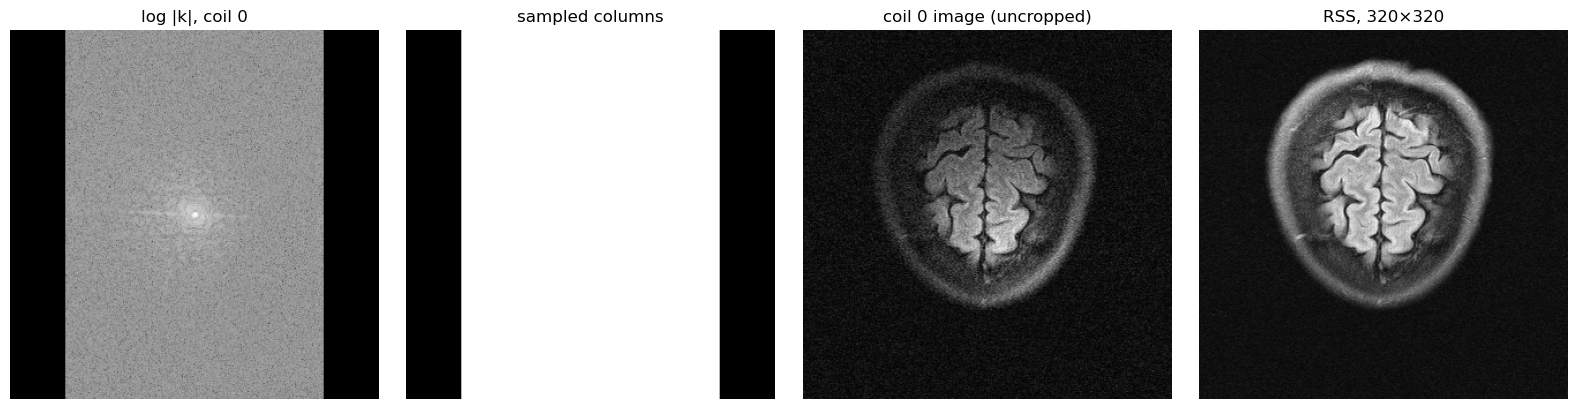

In [15]:
index16 = json.load(open("/egr/research-slim/luozishe/MSM-MRI/flow_matching/index_16x320x320.json"))
print(len(index16), "slices")
print(f"index16[10] = {index16[10]}")
z = np.load(index16[10])
for key in z.files:
    print(f"{key:20s} {str(z[key].shape):20s} {z[key].dtype}")
k = torch.from_numpy(z["kspace"])                      # adjust the key if it's named differently
sampled = k.abs().sum(dim=(0, 1)) > 0
print(f"coils={k.shape[0]}, H={k.shape[-2]}, W={k.shape[-1]} | {int(sampled.sum())}/{k.shape[-1]} columns sampled")

img = ifft2c(k)                                        # coil images
rss = img.abs().pow(2).sum(0).sqrt()      # already 320×320, no crop needed
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(torch.log(k[0].abs() + 1e-9), cmap="gray");          ax[0].set_title("log |k|, coil 0")
ax[1].imshow(sampled[None].expand(k.shape[-2], -1), cmap="gray"); ax[1].set_title("sampled columns")
ax[2].imshow(img[0].abs(), cmap="gray");                          ax[2].set_title("coil 0 image (uncropped)")
ax[3].imshow(rss, cmap="gray");                                   ax[3].set_title("RSS, 320×320")
for a in ax: a.axis("off")
plt.tight_layout()

In [17]:
model = build_unet(n_coils=N_COILS).to(device)
optim = torch.optim.AdamW(model.parameters(), lr=LR)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
vx, vA, _ = val_set[0]                          # vx = A x1: degraded k-space (16, 320, 320) complex

25.3M parameters


PSNR (recon vs. zero-filled input): -1.74 dB


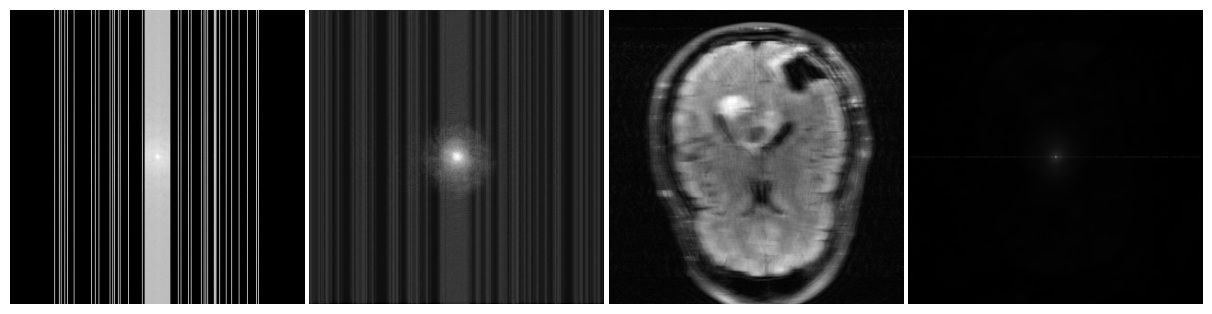

In [18]:
fix_y, fix_A = vx[None], vA[None]            # (1, 16, 320, 320), (1, 1, 1, 320)
psnr_val = plot_recon(model, fix_y, fix_A, t0=EPS)

In [ ]:
for i in range(MAX_STEPS):

    y, A, _ = next(train_data_iter)
    train_loss = ambient_loss(model, y, A, delta=DELTA, eps=EPS)

    optim.zero_grad(set_to_none=True)
    train_loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optim.step()
    train_losses.append(train_loss.item())

    if (i + 1) % val_every == 0:
        vy, vA, _ = next(val_data_iter)
        with torch.no_grad():
            model.eval()
            val_losses.append(ambient_loss(model, vy, vA, delta=DELTA, eps=EPS).item())
            model.train()
        val_steps.append(i + 1)
    
    if (i + 1) % print_every == 0:
        elapsed = time.time() - start_time
        clear_output(wait=True)
        print(f"| iter {i+1:6d} | {elapsed * 1000 / print_every:7.1f} ms/step | "
              f"train {np.mean(train_losses[-print_every:]):.4f} | "
              f"val {val_losses[-1] if val_losses else float('nan'):.4f}")

        # 1) loss curves so far
        plt.figure(figsize=(8, 3))
        plt.semilogy(train_losses, alpha=0.4, label="train")
        if val_losses: plt.semilogy(val_steps, val_losses, "o-", label="val")
        plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()

        # 2) reconstruction of the fixed slice
        plot_recon(model, fix_y, fix_A, t0=EPS)
        start_time = time.time()

    if (i + 1) % ckpt_every == 0:
        torch.save({"model": model.state_dict(), "opt": optim.state_dict(), "step": i + 1},
                   f"{ckpt_dir}/step_{i+1}.pt")